# Optimización de redes y rutas (TSP, m-TSP y más)

Cuaderno para resolver problemas de **grafos y rutas con métodos de optimización**: cada problema se
formula como un programa lineal o entero mixto y lo resuelve el solver exacto **HiGHS** (vía SciPy).

**No se usan algoritmos de grafos** (Dijkstra, Bellman-Ford, Floyd-Warshall, Prim, Kruskal…) **ni heurísticas**
(vecino más cercano, 2-opt, ahorros…). Cuando el solver termina en *óptimo*, la respuesta es el óptimo global
probado; si se acaba el tiempo, se informa la **brecha** respecto a la mejor cota.

| Familia | Problemas | Modelo |
|---|---|---|
| Rutas | TSP (circuito, camino abierto, camino origen→destino, camino libre), m-TSP, VRP con capacidad (CVRP), multidepósito | MILP |
| Caminos | camino mínimo origen→destino, desde un origen a todos, todos los pares | LP de flujo |
| Árboles | árbol de valor mínimo (o arborescencia si la red es dirigida) | MILP de flujo |
| Flujos | flujo máximo, flujo de costo mínimo, transporte, asignación | LP / MILP |
| Recorridos | cartero chino | MILP |
| Localización | p-mediana, p-centro, cobertura de conjuntos | MILP |
| Otros | cualquier modelo propio con la clase `Modelo` | LP / MILP |

**Cómo usarlo:** ejecute las celdas en orden. La sección 2 trae un **panel interactivo** (cargar datos → elegir
problema → resolver). Las secciones 3 a 6 muestran los mismos problemas por código, incluidos los casos del
parcial (China Top 25 y tiendas ARA de Cali).

## 1. Preparación

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import optgrafos as og

pd.set_option("display.max_columns", 40); pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 100
print("Solver: HiGHS vía SciPy · funciones:", [f for f in dir(og) if f in
      ("camino_minimo","todos_los_caminos","arbol_minimo","tsp","mtsp","cvrp","vrp","flujo_maximo",
       "flujo_costo_minimo","asignacion","transporte","cartero_chino","p_mediana","p_centro","cobertura")])

Solver: HiGHS vía SciPy · funciones: ['arbol_minimo', 'asignacion', 'camino_minimo', 'cartero_chino', 'cobertura', 'cvrp', 'flujo_costo_minimo', 'flujo_maximo', 'mtsp', 'p_centro', 'p_mediana', 'todos_los_caminos', 'transporte', 'tsp', 'vrp']


## 2. Panel interactivo

1. En **«1. Datos»** elija un ejemplo, una ruta de archivo (o súbalo) o pegue los datos y pulse **Cargar datos**.
2. En **«2. Problema»** elija el problema, escriba los nodos (por su etiqueta), ajuste parámetros y pulse **Resolver**.

**Formatos de datos aceptados** (CSV, TSV, Excel o texto pegado; `#` o vacío = no hay arco):

| Formato | Cómo debe verse | Se interpreta como |
|---|---|---|
| Matriz | primera fila y primera columna con etiquetas, valores = costo/distancia | matriz de costos |
| Aristas | columnas `origen, destino, costo` (+ `capacidad` opcional) | lista de aristas (marque «dirigidas» si aplica) |
| Coordenadas | columnas `lat, lon` (+ `id, nombre, demanda`) | distancia haversine × factor (km); `euclidiana` para x, y |

En el panel, los nodos se escriben **con la etiqueta de la red** (en Cali 0 = centro de distribución, 1–25 tiendas;
en China 1–25 = posición en el Top 25).

In [2]:
import panel
p = panel.Panel().mostrar()

## 3. Caso del parcial · Punto 1: China Top 25
Matriz de **km por carretera** entre las 25 ciudades; nodos etiquetados 1–25 según el Top 25.

In [3]:
china = og.ejemplo("china")
print(china)
china.df().iloc[:6, :6].round(1)

Red('China Top 25 (km por carretera)': 25 nodos, 600 arcos, no dirigida)


,1,2,3,4,5,6
1,0.0,1634.7,1752.3,303.0,1260.1,1378.8
2,1634.7,0.0,1203.7,1898.9,1406.4,1405.6
3,1752.3,1203.7,0.0,1797.4,2124.9,2146.0
4,303.0,1898.9,1797.4,0.0,1537.0,1665.3
5,1260.1,1406.4,2124.9,1537.0,0.0,131.8
6,1378.8,1405.6,2146.0,1665.3,131.8,0.0


### 3.1 Camino mínimo: origen Top 1–10 → destino Top 15–25
Se resuelve **un programa lineal de flujo por origen** (equivalente a Floyd-Warshall, pero por optimización).

In [4]:
todos = og.todos_los_caminos(china)
M = todos.tablas["distancias"]
print(todos.resumen())
origenes, destinos = list(range(1, 11)), list(range(15, 26))
M.loc[origenes, destinos].round(1)

Problema : Todos los caminos mínimos (n LP de flujo)
Estado   : óptimo
Tiempo   : 0.386 s


,15,16,17,18,19,20,21,22,23,24,25
1,2411.8,1808.8,1526.9,2958.8,798.0,828.0,1571.1,1219.2,917.9,1471.6,2699.0
2,1685.0,709.5,809.7,2232.0,1027.8,2278.4,94.6,464.6,1835.2,1108.4,1972.2
3,686.5,644.6,399.5,1222.2,1473.7,2536.6,1138.7,1019.3,2306.0,291.1,962.4
4,2456.9,1889.4,1622.0,3003.9,1101.0,809.1,1837.6,1481.1,1178.7,1516.7,2744.1
5,2746.2,1863.2,1819.2,3293.2,679.1,1328.8,1379.8,1203.7,557.3,1856.2,3033.4
6,2761.7,1887.4,1860.0,3308.7,780.0,1417.6,1379.0,1227.8,646.1,1934.7,3048.9
7,1763.9,1011.6,834.3,2310.9,331.9,1531.9,703.0,360.8,1191.4,896.0,2051.1
8,644.2,550.8,352.2,1191.2,1479.5,2579.0,1055.1,972.3,2306.4,330.9,931.4
9,1729.2,1172.9,905.6,2276.2,976.6,1469.4,1297.1,922.0,1598.8,789.0,2016.4
10,1326.9,715.3,448.0,1873.9,802.3,1914.6,872.0,552.0,1640.8,416.5,1614.1


In [5]:
# mejor destino (el más cercano del Top 15–25) para cada origen del Top 1–10
sub = M.loc[origenes, destinos]
mejor = pd.DataFrame({"destino más cercano": sub.idxmin(axis=1), "distancia (km)": sub.min(axis=1).round(1)})
mejor["ruta"] = [" → ".join(map(str, todos.ruta(o, d))) for o, d in zip(mejor.index, mejor["destino más cercano"])]
mejor

,destino más cercano,distancia (km),ruta
1,19,798.0,1 → 19
2,21,94.6,2 → 21
3,24,291.1,3 → 24
4,20,809.1,4 → 20
5,23,557.3,5 → 23
6,23,646.1,6 → 23
7,19,331.9,7 → 19
8,24,330.9,8 → 24
9,24,789.0,9 → 24
10,24,416.5,10 → 24


In [6]:
# detalle de un par: Shanghái (2) → Changchun (25)
r = og.camino_minimo(china, 2, 25)
print(r.resumen()); print("Ruta:", " → ".join(china.etq(china.idx(u)) for u in r.rutas[0]))
r.tablas["caminos"]

Problema : Camino mínimo (LP de flujo)
Estado   : óptimo
Objetivo : 1972.2
Tiempo   : 0.023 s
Ruta: 2 (Shanghái) → 15 (Shenyang) → 25 (Changchun)


,origen,destino,distancia,ruta
0,2,25,1972.2,2 → 15 → 25


### 3.2 Árbol de valor mínimo con raíz en el Top 11–20

raíz 11: costo total = 8130.1 km · 24 aristas · óptimo · 1.915 s


raíz 15: costo total = 8130.1 km · 24 aristas · óptimo · 3.526 s


raíz 20: costo total = 8130.1 km · 24 aristas · óptimo · 3.133 s


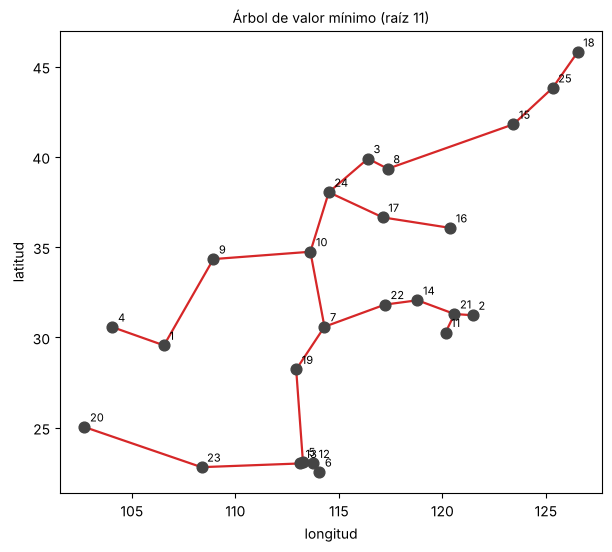

,desde,hasta,costo
0,1,4,303.0
1,3,8,121.9
2,5,12,61.9
3,5,13,26.1
4,7,10,510.8
5,7,19,331.9
6,8,15,644.2
7,1,9,693.0
8,9,10,479.7
9,10,24,416.5


In [7]:
for raiz in (11, 15, 20):
    a = og.arbol_minimo(china, raiz)
    print(f"raíz {raiz:>2}: costo total = {a.objetivo:.1f} km · {len(a.arcos)} aristas · {a.estado} · {a.segundos} s")
a = og.arbol_minimo(china, 11)
fig, ax = plt.subplots(figsize=(7, 6)); og.dibujar(china, a, ax=ax, titulo="Árbol de valor mínimo (raíz 11)"); plt.show()
a.tablas["arcos_del_arbol"]

### 3.3 TSP y m-TSP en China

In [8]:
t = og.tsp(china, 1)
print(t.resumen()); print(" → ".join(map(str, t.rutas[0])))
m2 = og.mtsp(china, 2, deposito=1)
print(m2.resumen()); m2.tablas["rutas"]

Problema : TSP (circuito) - MILP DFJ
Estado   : óptimo
Objetivo : 10423.3
Brecha   : 0.00e+00
Tiempo   : 0.113 s
1 → 9 → 10 → 24 → 3 → 18 → 25 → 15 → 8 → 17 → 16 → 21 → 2 → 11 → 14 → 22 → 7 → 19 → 6 → 12 → 5 → 13 → 23 → 20 → 4 → 1
Problema : m-TSP con m=2 (MILP)
Estado   : óptimo
Objetivo : 10745.2
Brecha   : 0.00e+00
Tiempo   : 0.109 s
Distancia total = 10745.200; ruta más larga = 10139.200


,vehículo,ruta,clientes,carga,distancia
0,1,1 → 9 → 10 → 24 → 3 → 18 → 25 → 15 → 8 → 17 → ...,23,0.0,10139.2
1,2,1 → 4 → 1,1,0.0,606.0


## 4. Caso del parcial · Punto 2: 25 tiendas ARA en Cali
Nodo **0 = centro de distribución** (provisional, centroide de las tiendas hasta definirlo con anyLogistix) y nodos 1–25 = tiendas.
Distancias **por carretera** (OSRM sobre OpenStreetMap).

In [9]:
cali = og.ejemplo("cali")
print(cali)
pd.DataFrame({"nodo": cali.ids, "nombre": cali.nombres, "lat": cali.coords[:, 0], "lon": cali.coords[:, 1]}).head(8)

Red('Cali ARA (km por carretera)': 26 nodos, 650 arcos, no dirigida)


,nodo,nombre,lat,lon
0,0,CD central (provisional),3.425415,-76.514309
1,1,Cali - VALLE GRANDE,3.394598,-76.524377
2,2,Cali - LOS ALAMOS,3.478631,-76.516804
3,3,Cali - PORVENIR CALI,3.424276,-76.511981
4,4,Cali - Quintas Don Simon,3.387378,-76.532607
5,5,Cali - Los Lagos,3.441389,-76.490049
6,6,Cali - Valle de Lili,3.387385,-76.518374
7,7,Cali - Capri,3.431836,-76.539266


### 4.1 TSP: un solo supervisor visita las 25 tiendas y regresa

Problema : TSP (circuito) - MILP DFJ
Estado   : óptimo
Objetivo : 72.048
Brecha   : 0.00e+00
Tiempo   : 0.083 s
Cortes de subtour añadidos: 23


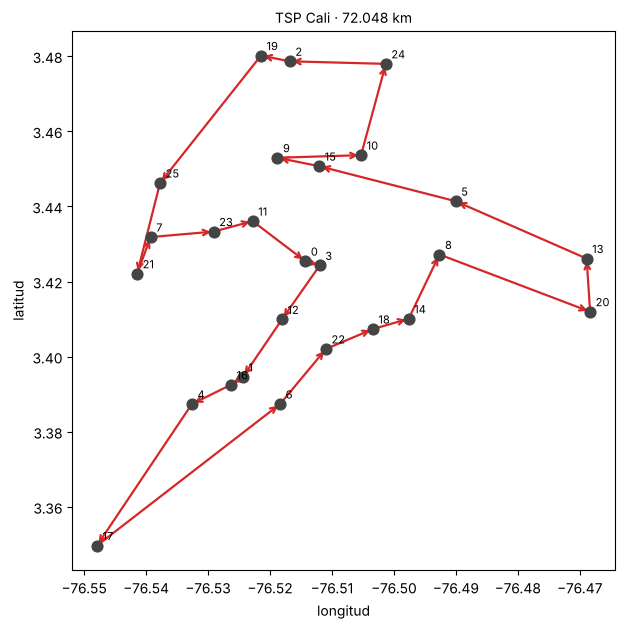

,orden,nodo,nombre,tramo_km,acumulado
0,0,0,CD central (provisional),0.000,0.000
1,1,3,Cali - PORVENIR CALI,0.489,0.489
2,2,12,Cali - Republica de Israel,2.293,2.782
3,3,1,Cali - VALLE GRANDE,2.629,5.411
4,4,16,Cali - Caldas,0.893,6.304
5,5,4,Cali - Quintas Don Simon,1.645,7.949
6,6,17,Cali - Alameda Av Roosevelt,5.665,13.614
7,7,6,Cali - Valle de Lili,7.827,21.441
8,8,22,Cali - Caney,2.385,23.826
9,9,18,Cali - Antonio Nariño,1.257,25.083


In [10]:
t = og.tsp(cali, 0)
print(t.resumen()); print("Cortes de subtour añadidos:", t.extra["cortes"])
fig, ax = plt.subplots(figsize=(7, 7)); og.dibujar(cali, t, ax=ax, titulo=f"TSP Cali · {t.objetivo:.3f} km"); plt.show()
t.tablas["ruta"]

### 4.2 m-TSP con 2 supervisores
Sin límites por ruta el óptimo puede dejar casi todas las tiendas a un solo supervisor. Se muestran tres variantes.

In [11]:
resultados_mtsp = {}
resultados_mtsp["2 supervisores · sin límites"] = og.mtsp(cali, 2, 0, lmin=1)
resultados_mtsp["2 supervisores · 12 y 13 tiendas"] = og.mtsp(cali, 2, 0, lmin=12, lmax=13)
resultados_mtsp["2 supervisores · ruta más larga mínima"] = og.mtsp(cali, 2, 0, lmin=1, objetivo="maximo", tiempo=120)
for nombre, r in resultados_mtsp.items():
    print("•", nombre, "→", r.estado, "| objetivo", round(r.objetivo, 3), "|", r.mensaje, f"| {r.segundos} s")
resultados_mtsp["2 supervisores · 12 y 13 tiendas"].tablas["rutas"]

• 2 supervisores · sin límites → óptimo | objetivo 72.436 | Distancia total = 72.436; ruta más larga = 71.458 | 0.104 s
• 2 supervisores · 12 y 13 tiendas → óptimo | objetivo 75.675 | Distancia total = 75.675; ruta más larga = 43.017 | 14.308 s
• 2 supervisores · ruta más larga mínima → óptimo | objetivo 39.841 | Distancia total = 78.437; ruta más larga = 39.841 | 53.962 s


,vehículo,ruta,clientes,carga,distancia
0,1,0 → 8 → 5 → 13 → 20 → 14 → 18 → 22 → 6 → 17 → ...,13,0.0,43.017
1,2,0 → 23 → 7 → 21 → 25 → 19 → 2 → 24 → 10 → 15 →...,12,0.0,32.658


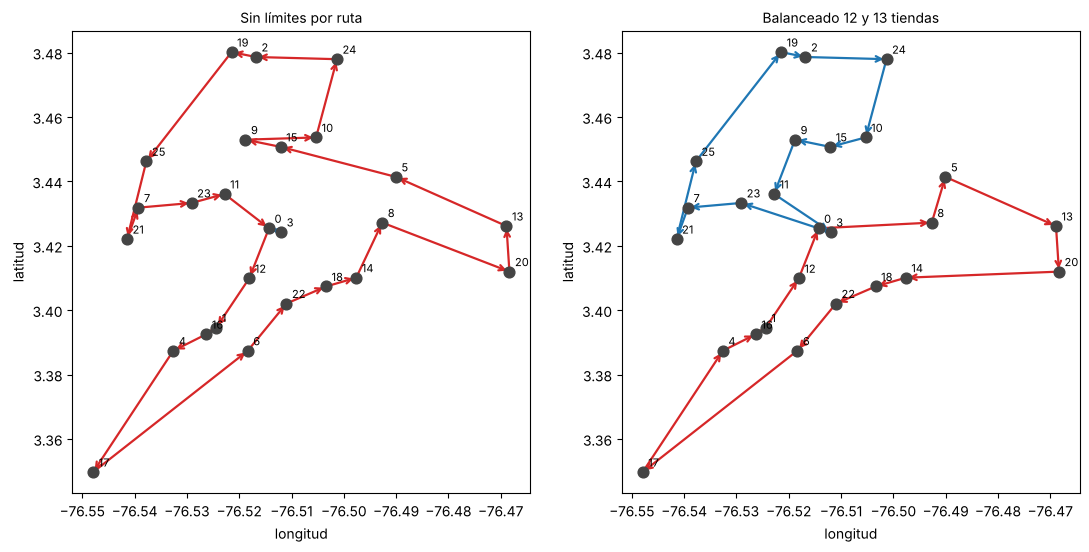

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
og.dibujar(cali, resultados_mtsp["2 supervisores · sin límites"], ax=axes[0], titulo="Sin límites por ruta")
og.dibujar(cali, resultados_mtsp["2 supervisores · 12 y 13 tiendas"], ax=axes[1], titulo="Balanceado 12 y 13 tiendas")
plt.show()

### 4.3 m = 3 supervisores

In [13]:
r3 = og.mtsp(cali, 3, 0, lmin=8, lmax=9, tiempo=200)
print(r3.resumen()); r3.tablas["rutas"]

Problema : m-TSP con m=3 (MILP)
Estado   : óptimo
Objetivo : 81.53
Brecha   : 0.00e+00
Tiempo   : 79.329 s
Distancia total = 81.530; ruta más larga = 28.997


,vehículo,ruta,clientes,carga,distancia
0,1,0 → 12 → 1 → 16 → 4 → 17 → 6 → 22 → 18 → 14 → 0,9,0.0,28.997
1,2,0 → 3 → 8 → 20 → 13 → 5 → 15 → 9 → 11 → 0,8,0.0,23.856
2,3,0 → 10 → 24 → 2 → 19 → 25 → 21 → 7 → 23 → 0,8,0.0,28.677


## 5. Más problemas (los mismos que resuelve el panel)

### 5.1 TSP: variantes de recorrido

In [14]:
variantes = {
    "circuito (regresa al CD)":          og.tsp(cali, 0, "ciclo"),
    "camino abierto desde el CD":        og.tsp(cali, 0, "abierto"),
    "camino del CD (0) a la tienda 25":  og.tsp(cali, 0, "fijo", fin=25),
    "camino libre (inicio y fin libres)": og.tsp(cali, modo="libre"),
}
pd.DataFrame([{"variante": k, "km": round(v.objetivo, 3), "estado": v.estado, "s": v.segundos,
               "recorrido": " → ".join(map(str, v.rutas[0]))} for k, v in variantes.items()])

,variante,km,estado,s,recorrido
0,circuito (regresa al CD),72.048,óptimo,0.108,0 → 3 → 12 → 1 → 16 → 4 → 17 → 6 → 22 → 18 → 1...
1,camino abierto desde el CD,65.877,óptimo,0.097,0 → 3 → 11 → 23 → 7 → 21 → 25 → 19 → 2 → 24 → ...
2,camino del CD (0) a la tienda 25,69.191,óptimo,0.077,0 → 3 → 12 → 1 → 16 → 4 → 17 → 6 → 22 → 18 → 1...
3,camino libre (inicio y fin libres),63.437,óptimo,0.344,17 → 4 → 1 → 16 → 6 → 12 → 22 → 18 → 14 → 20 →...


### 5.2 m-TSP con depósitos distintos, rutas abiertas y VRP con capacidad

In [15]:
# dos supervisores que salen de depósitos distintos (nodos 0 y 13) y regresan a su depósito
md_ = og.vrp(cali, 2, deposito=[0, 13], lmin=5, problema="m-TSP multidepósito")
print(md_.resumen()); print(md_.tablas["rutas"].to_string(index=False))
# rutas abiertas: los supervisores no regresan
ab = og.mtsp(cali, 2, 0, lmin=12, lmax=13, abierto=True)
print("\nRutas abiertas:", ab.estado, round(ab.objetivo, 3), "km")

Problema : m-TSP multidepósito
Estado   : óptimo
Objetivo : 73.46
Brecha   : 0.00e+00
Tiempo   : 35.003 s
Distancia total = 73.460; ruta más larga = 44.463
 vehículo                                                                     ruta  clientes  carga  distancia
        1                      0 → 3 → 14 → 18 → 22 → 6 → 17 → 4 → 16 → 1 → 12 → 0        10    0.0     28.997
        2 13 → 20 → 8 → 11 → 23 → 7 → 21 → 25 → 19 → 2 → 24 → 10 → 9 → 15 → 5 → 13        14    0.0     44.463



Rutas abiertas: óptimo 63.673 km


In [16]:
# CVRP: 4 vehículos de capacidad 60 con una demanda ilustrativa por tienda (¡reemplace por la real!)
demanda = {i: 5 + (i * 7) % 9 for i in range(1, 26)}
cv = og.cvrp(cali, 4, 60, demanda, deposito=0, tiempo=60)
print(cv.resumen()); cv.tablas["rutas"]

Problema : CVRP (MILP)
Estado   : límite de tiempo (mejor solución encontrada, no probada óptima)
Objetivo : 93.129
Brecha   : 1.37e-01
Tiempo   : 60.029 s
Distancia total = 93.129; ruta más larga = 26.639


,vehículo,ruta,clientes,carga,distancia
0,1,0 → 22 → 6 → 17 → 4 → 16 → 1 → 12 → 0,7,59.0,26.639
1,2,0 → 10 → 24 → 2 → 19 → 23 → 0,5,58.0,23.735
2,3,0 → 3 → 15 → 9 → 25 → 21 → 7 → 11 → 0,7,60.0,20.429
3,4,0 → 14 → 18 → 8 → 20 → 13 → 5 → 0,6,54.0,22.326


### 5.3 Caminos, flujos, asignación, transporte, cartero chino y localización sobre redes pequeñas

In [17]:
# red clásica de 6 nodos (no dirigida)
red = og.Red.desde_aristas([(1,2,7),(1,3,9),(1,6,14),(2,3,10),(2,4,15),(3,4,11),(3,6,2),(4,5,6),(5,6,9)], titulo="ejemplo 6 nodos")
c = og.camino_minimo(red, 1, 5); print(c.resumen()); print("Ruta:", c.rutas[0])
print(og.camino_minimo(red, 1).tablas["caminos"].to_string(index=False))
arb = og.arbol_minimo(red); print("\nÁrbol mínimo:", arb.objetivo, arb.arcos)

Problema : Camino mínimo (LP de flujo)
Estado   : óptimo
Objetivo : 20.0
Tiempo   : 0.008 s
Ruta: [1, 3, 6, 5]
 origen  destino  distancia          ruta
      1        2        7.0         1 → 2
      1        3        9.0         1 → 3
      1        4       20.0     1 → 3 → 4
      1        5       20.0 1 → 3 → 6 → 5
      1        6       11.0     1 → 3 → 6

Árbol mínimo: 33.0 [(1, 2, np.float64(7.0)), (1, 3, np.float64(9.0)), (3, 6, np.float64(2.0)), (4, 5, np.float64(6.0)), (5, 6, np.float64(9.0))]


In [18]:
# flujo máximo y flujo de costo mínimo en una red dirigida con capacidades
cap = og.Red.desde_aristas([(1,2,4,6),(1,3,2,5),(2,3,1,3),(2,4,5,4),(3,4,3,8),(3,5,6,5),(4,5,1,7)], dirigido=True)
print("Flujo máximo 1→5:", og.flujo_maximo(cap, 1, 5).objetivo)
fcm = og.flujo_costo_minimo(cap, {1: 8, 5: -8})
print("Flujo de costo mínimo (8 unidades de 1 a 5):", fcm.objetivo); fcm.tablas["flujo_por_arco"]

Flujo máximo 1→5: 11.0
Flujo de costo mínimo (8 unidades de 1 a 5): 59.0


,desde,hasta,flujo,costo_unitario
0,1,2,3.0,4.0
1,1,3,5.0,2.0
2,2,3,3.0,1.0
3,3,4,7.0,3.0
4,3,5,1.0,6.0
5,4,5,7.0,1.0


In [19]:
# asignación y transporte
costos = pd.DataFrame([[9,2,7,8],[6,4,3,7],[5,8,1,8],[7,6,9,4]], index=list("ABCD"), columns=[1,2,3,4])
print("Asignación:", og.asignacion(costos).objetivo, og.asignacion(costos).arcos)
C = pd.DataFrame([[8,6,10,9],[9,12,13,7],[14,9,16,5]], index=["P1","P2","P3"], columns=["D1","D2","D3","D4"])
tr = og.transporte(C, oferta=[35, 50, 40], demanda=[45, 20, 30, 30])
print("\nTransporte:", tr.objetivo); tr.tablas["envios"]

Asignación: 13.0 [('A', np.int64(2), 2.0), ('B', np.int64(1), 6.0), ('C', np.int64(3), 1.0), ('D', np.int64(4), 4.0)]

Transporte: 1020.0


,origen,destino,cantidad,costo_unitario
0,P1,D2,10.0,6.0
1,P1,D3,25.0,10.0
2,P2,D1,45.0,9.0
3,P2,D3,5.0,13.0
4,P3,D2,10.0,9.0
5,P3,D4,30.0,5.0


In [20]:
# cartero chino y localización
cc = og.cartero_chino(og.Red.desde_aristas([(1,2,3),(2,3,4),(3,1,5),(3,4,2)]))
print(cc.resumen()); print(cc.tablas["aristas"].to_string(index=False))
pm = og.p_mediana(china, 3); pc = og.p_centro(china, 3); cb = og.cobertura(china, 1500)
print("\np-mediana (3):", pm.mensaje, "→", round(pm.objetivo, 1))
print("p-centro  (3):", pc.mensaje, "→", round(pc.objetivo, 1))
print("cobertura R=1500 km:", cb.mensaje)

Problema : Cartero chino (MILP)
Estado   : óptimo
Objetivo : 16.0
Tiempo   : 0.007 s
Costo de las aristas = 14.000; recorrido repetido = 2.000
 desde  hasta  costo  veces
     1      2    3.0      1
     1      3    5.0      1
     2      3    4.0      1
     3      4    2.0      2



p-mediana (3): Instalaciones abiertas: [7, 8, 13] → 12839.3
p-centro  (3): Instalaciones abiertas: [7, 15, 20] → 1054.9
cobertura R=1500 km: Instalaciones: [19, 24]


## 6. Modelo propio con la clase `Modelo`
Cualquier otro problema se arma agregando variables y restricciones. Ejemplo: **camino de costo mínimo que usa a lo sumo $L$ arcos**
(el LP de flujo más una restricción extra sobre la cantidad de arcos).

In [21]:
def camino_con_limite(red, s, t, L):
    s, t = red.idx(s), red.idx(t)
    arcos = red.arcos()
    M = og.Modelo()
    f = [M.var(c, 0, 1, entera=True) for _, _, c in arcos]
    for u in range(red.n):
        sal = [f[a] for a, (i, j, _) in enumerate(arcos) if i == u]
        ent = [f[a] for a, (i, j, _) in enumerate(arcos) if j == u]
        b = 1 if u == s else (-1 if u == t else 0)
        M.restr(sal + ent, [1.0] * len(sal) + [-1.0] * len(ent), b, b)
    M.restr(f, 1.0, hi=L)                          # a lo sumo L arcos
    sol = M.resolver()
    return sol.estado, sol.obj, [(red.ids[i], red.ids[j]) for a, (i, j, _) in enumerate(arcos) if sol.ok and sol.x[f[a]] > .5]

for L in (2, 3, 4):
    print(L, camino_con_limite(red, 1, 5, L))

2 ('óptimo', 23.0, [(1, 6), (6, 5)])
3 ('óptimo', 20.0, [(1, 3), (3, 6), (6, 5)])
4 ('óptimo', 20.0, [(1, 3), (3, 6), (6, 5)])


## 7. Exportar resultados

In [22]:
with pd.ExcelWriter("resultados_optimizacion.xlsx") as xw:
    resumen = pd.DataFrame([
        {"caso": "TSP Cali (circuito)", "km": t.objetivo, "estado": t.estado, "segundos": t.segundos},
        *[{"caso": "m-TSP Cali · " + k, "km": v.objetivo, "estado": v.estado, "segundos": v.segundos} for k, v in resultados_mtsp.items()],
        {"caso": "m-TSP Cali · 3 supervisores 8–9", "km": r3.objetivo, "estado": r3.estado, "segundos": r3.segundos},
        {"caso": "Árbol mínimo China (raíz 11)", "km": a.objetivo, "estado": a.estado, "segundos": a.segundos},
    ])
    resumen.to_excel(xw, sheet_name="resumen", index=False)
    t.tablas["ruta"].to_excel(xw, sheet_name="TSP_Cali", index=False)
    resultados_mtsp["2 supervisores · 12 y 13 tiendas"].tablas["rutas"].to_excel(xw, sheet_name="mTSP_Cali_12_13", index=False)
    M.loc[origenes, destinos].round(1).to_excel(xw, sheet_name="China_caminos_1-10_a_15-25")
    mejor.to_excel(xw, sheet_name="China_mejor_destino")
    a.tablas["arcos_del_arbol"].to_excel(xw, sheet_name="China_arbol", index=False)
resumen.round(3)

,caso,km,estado,segundos
0,TSP Cali (circuito),72.048,óptimo,0.083
1,m-TSP Cali · 2 supervisores · sin límites,72.436,óptimo,0.104
2,m-TSP Cali · 2 supervisores · 12 y 13 tiendas,75.675,óptimo,14.308
3,m-TSP Cali · 2 supervisores · ruta más larga m...,39.841,óptimo,53.962
4,m-TSP Cali · 3 supervisores 8–9,81.530,óptimo,79.329
5,Árbol mínimo China (raíz 11),8130.100,óptimo,1.764


## 8. Formulaciones usadas
Sea $c_{ij}$ el costo del arco $(i,j)$ y $n$ el número de nodos.

**Camino mínimo (LP de flujo).** $\min \sum c_{ij}f_{ij}$ sujeto a $\sum_j f_{ij}-\sum_j f_{ji}=b_i$ con $b_s=1$, $b_t=-1$, $b_i=0$ en los demás; $f\ge 0$.
Para todos los destinos se envía una unidad a cada nodo; la matriz completa son $n$ programas lineales.

**Árbol de valor mínimo (MILP de flujo).** Variables binarias $y_{ij}$ (arco usado) y continuas $f_{ij}$ (flujo desde la raíz $r$):
$\min\sum c_{ij}y_{ij}$; $\sum_i y_{ij}=1$ para $j\ne r$; $\sum_i y_{ir}=0$; la raíz emite $n-1$ unidades, cada otro nodo consume 1; $f_{ij}\le (n-1)\,y_{ij}$.

**TSP.** $x_{ij}\in\{0,1\}$; $\sum_j x_{ij}=1$, $\sum_i x_{ij}=1$; eliminación de subtours de Dantzig-Fulkerson-Johnson
$\sum_{i,j\in S}x_{ij}\le |S|-1$ agregada cuando la solución contiene un subcircuito $S$ (se resuelve de nuevo hasta que quede un solo circuito),
o la formulación compacta MTZ $u_i-u_j+(n-1)x_{ij}\le n-2$. Los caminos abiertos se obtienen con un nodo ficticio de costo cero.

**m-TSP / VRP.** $x_{ijk}$ (vehículo $k$ recorre $(i,j)$), $y_{ik}$ (cliente $i$ asignado a $k$): cada cliente a un solo vehículo $\sum_k y_{ik}=1$;
cada vehículo sale y regresa del depósito una vez; $\sum_j x_{jik}=\sum_j x_{ijk}=y_{ik}$; balance $l_{\min}\le\sum_i y_{ik}\le l_{\max}$;
capacidad $\sum_i q_i y_{ik}\le Q$; subtours: $\sum_{i,j\in S}x_{ijk}\le\sum_{i\in S\setminus\{h\}}y_{ik}$.
Objetivo: $\min\sum c_{ij}x_{ijk}$ o $\min z$ con $z\ge\sum c_{ij}x_{ijk}\ \forall k$.

**Flujos y asignación.** Flujo máximo: $\max v$ con conservación y $0\le f\le u$. Flujo de costo mínimo, transporte y asignación: LP/MILP clásicos de redes.

**Cartero chino.** $x_e\ge 1$ entero (veces que se recorre la arista $e$), grado par en cada nodo: $\sum_{e\ni v}x_e=2z_v$, $z_v\in\mathbb Z_{\ge0}$.

**Localización.** $p$-mediana: $\min\sum w_i d_{ij}x_{ij}$, $x_{ij}\le y_j$, $\sum_j y_j=p$. $p$-centro: $\min z$, $z\ge d_{ij}x_{ij}$.

## 9. Límites y buenas prácticas
* Los modelos son **exactos**: el tiempo crece con el tamaño. TSP de 25–40 nodos suele resolver en segundos; m-TSP, CVRP y p-centro con 25+ nodos pueden tardar más. Use `tiempo=` y revise `brecha`.
* Una solución con estado *«límite de tiempo»* es factible pero **no probada óptima**; la brecha indica la distancia a la mejor cota.
* Las matrices se interpretan **tal cual**: una distancia por carretera puede violar la desigualdad triangular (camino mínimo ≠ arco directo).
* Con distancias en línea recta (`Red.desde_coordenadas`) los resultados serán menores que por carretera; cite siempre cuál usó.